Computer Vision is a field of Artificial Intelligence that enables computers to interpret, analyse and extract meaningful information from images and videos.


Real-life examples

1) Retail analytics
Detect products, monitor shelves, analyse customer movement and automate checkout processes.

2) Automotive
Identify pedestrians, traffic signals, vehicles and road boundaries.

3) Manufacturing
Detect scratches, defects and missing components on production lines.

4) Document processing
Extract text from invoices, receipts, identity documents and forms using OCR systems.

Terms

Image Preprocessing ---- Modify or enhance an image
image Recognition ---- identify what an image contains
Image Detection  ---- identify objects and their locations
Image Segmentation ---- Classify pixels or separate object Groups
Computer Vision ---- Broad Field covering these and other visuals tasks

In [1]:
pip install opencv-python

Note: you may need to restart the kernel to use updated packages.


READING IMAGES

cv2.IMREAD_COLOR: It specifies to load a color image. Any transparency of image will be neglected. It is the default flag. Alternatively, we can pass integer value 1 for this flag.

cv2.IMREAD_GRAYSCALE: It specifies to load an image in grayscale mode. Alternatively, we can pass integer value 0 for this flag.

cv2.IMREAD_UNCHANGED: It specifies to load an image as such including alpha channel. Alternatively, we can pass integer value -1 for this flag.


In [2]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

In [3]:
color_img = cv2.imread('OIP.jpeg',cv2.IMREAD_COLOR)

gray_img = cv2.imread('OIP.jpeg',cv2.IMREAD_GRAYSCALE)

alpha_img = cv2.imread('Tree.jpeg',cv2.IMREAD_UNCHANGED)

In [4]:
color_img.shape 

# 266 hight ,474 width and 3 channels (RGB)
# That 3 Means there is 3 2d arrays inside the 3d array.
# each 2d array is one channel like RED
# second 2d array --> Blue Channel
# third 2d array --> Green Channel

(266, 474, 3)

In [5]:
gray_img.shape 

(266, 474)

In [6]:
alpha_img.shape 

(381, 225, 3)

In [7]:
color_img

array([[[ 57,  58,  56],
        [ 57,  58,  56],
        [ 57,  58,  56],
        ...,
        [ 54,  55,  53],
        [ 52,  53,  51],
        [ 52,  53,  51]],

       [[ 57,  58,  56],
        [ 57,  58,  56],
        [ 57,  58,  56],
        ...,
        [ 54,  55,  53],
        [ 52,  53,  51],
        [ 52,  53,  51]],

       [[ 58,  59,  57],
        [ 58,  59,  57],
        [ 58,  59,  57],
        ...,
        [ 55,  56,  54],
        [ 51,  52,  50],
        [ 51,  52,  50]],

       ...,

       [[ 92,  85,  88],
        [ 90,  85,  86],
        [ 85,  86,  84],
        ...,
        [109, 104, 105],
        [110, 104,  99],
        [114, 104,  97]],

       [[105,  97,  98],
        [ 95,  90,  89],
        [ 88,  87,  83],
        ...,
        [110, 106, 105],
        [115, 109, 104],
        [120, 112, 105]],

       [[105,  97,  98],
        [ 95,  90,  89],
        [ 88,  87,  83],
        ...,
        [110, 106, 105],
        [115, 109, 104],
        [120, 112, 105]]

In [8]:
cv2.imshow('Color Image', color_img)
cv2.waitKey(5000) 
# if 0 is given then we have to cut the window manually
# if 5000 is given then image will be displayed for 5 seconds and then window will be closed automatically
# 1000 is equals 1 second

cv2.destroyAllWindows()

In [9]:
cv2.imshow('Gray Image', gray_img)
cv2.waitKey(5000)
cv2.destroyAllWindows()

In [10]:
cv2.imshow('Alpha Image', alpha_img)
cv2.waitKey(5000)
cv2.destroyAllWindows()

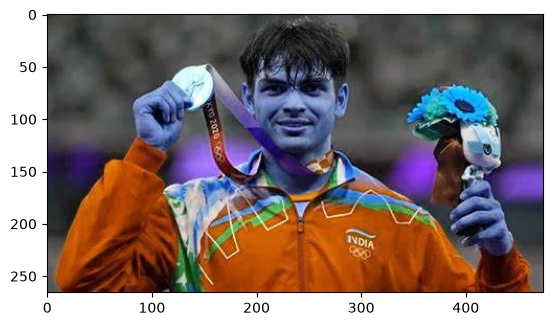

In [11]:
plt.imshow(color_img)

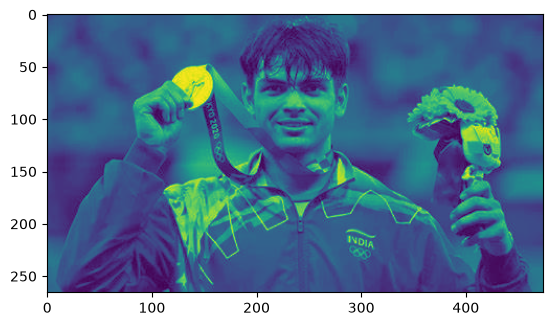

In [12]:
plt.imshow(gray_img)

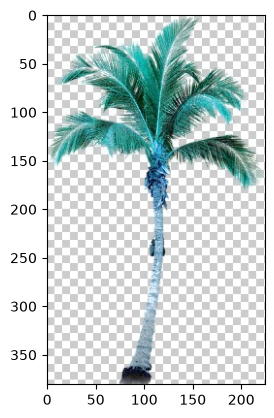

In [13]:
plt.imshow(alpha_img)

In [14]:
# Saving The Imahges That we have read in grayscale 

cv2.imwrite('Gray_Image.jpg',gray_img)

True

In [15]:
# Extract RGB Pixels Values

B,G,R = cv2.split(color_img)

# Blue Channel
cv2.imshow('Blue Channel',B)
cv2.waitKey(5000)
cv2.imshow('Green Channel',G)
cv2.waitKey(5000)
cv2.imshow('Red Channel',R)
cv2.waitKey(5000)
cv2.destroyAllWindows()

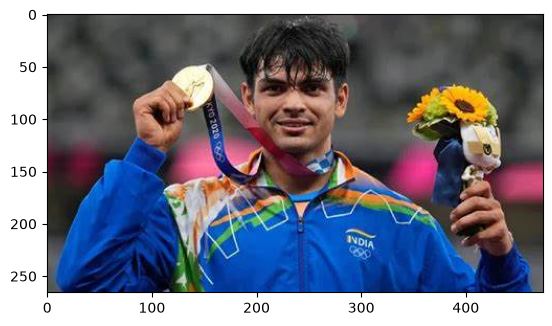

In [16]:
# Extracting region of interest (ROI) from the image

RGB = cv2.cvtColor(color_img, cv2.COLOR_BGR2RGB)
plt.imshow(RGB)

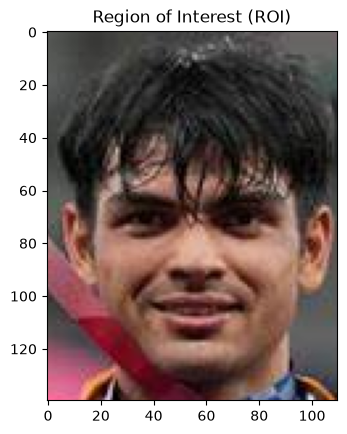

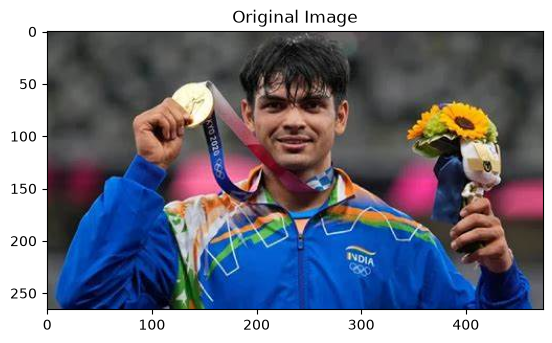

In [26]:
img = cv2.imread("OIP.jpeg")

roi = img[0:140,180:290] # [y1:y2,x1:x2]

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
roi_rgb = cv2.cvtColor(roi, cv2.COLOR_BGR2RGB)

plt.title("Region of Interest (ROI)")
plt.imshow(roi_rgb)
plt.show()

plt.title("Original Image")
plt.imshow(img_rgb)
plt.show()

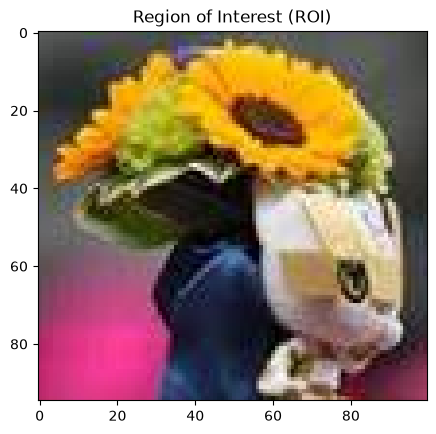

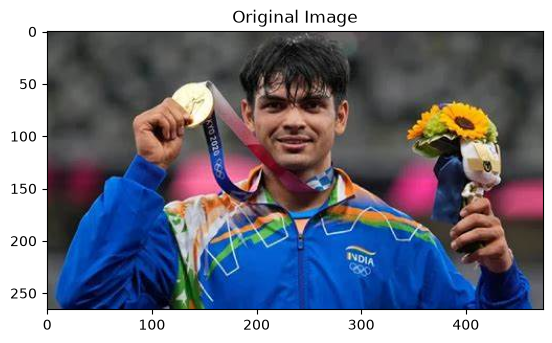

In [30]:
img = cv2.imread("OIP.jpeg")

roi = img[65:160,340:440] # [y1:y2,x1:x2]

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
roi_rgb = cv2.cvtColor(roi, cv2.COLOR_BGR2RGB)

plt.title("Region of Interest (ROI)")
plt.imshow(roi_rgb)
plt.show()

plt.title("Original Image")
plt.imshow(img_rgb)
plt.show()

In [34]:
# Extracting Height and Width Of The Image

image = cv2.imread("OIP.jpeg")

print(img.shape)
h,w = image.shape[:2]

print("Height of the image is: ",h)
print("Width of the image is: ",w)


(266, 474, 3)
Height of the image is:  266
Width of the image is:  474


<> RESIZING THE IMAGE

Resizing an image can be done in many ways. We will look into examples demonstrating the following resize operations.

1.Preserve Aspect Ratio (height to width ratio of image is preserved)

a) Downscale (Decrease the size of the image)

b) Upscale (Increase the size of the image)

2.Do not preserve Aspect Ratio

a) Resize only the width (Increase or decrease the width of the image keeping height unchanged)

b) Resize only the height (Increase or decrease the height of the image keeping width unchanged)

c) Resize to specific width and height

Choice of Interpolation Method for Resizing:

cv2.INTER_AREA: This is used when we need to shrink an image.

cv2.INTER_CUBIC: This is slow but more efficient.

cv2.INTER_LINEAR: This is primarily used when zooming is required. This is the default interpolation technique in OpenCV.

In [ ]:
# Preserve The Ratio -- Downscale the image

cv2.imread("OIP.jpeg")
print("Original Dimensions : ",img.shape)

scale_percent = 60 # percent of original size
width = int(img.shape[1] * scale_percent / 100)
height = int(img.shape[0] * scale_percent / 100)

dim = (width, height)

#resize image
resized = cv2.resize(img, dim, interpolation=cv2.INTER_AREA)
print("Resized Dimensions : ",resized.shape)

cv2.imshow("Original image", img)
cv2.waitKey(0)
cv2.imshow("Resized image", resized)
cv2.waitKey(0)
cv2.destroyAllWindows()

Original Dimensions :  (266, 474, 3)
Resized Dimensions :  (159, 284, 3)


In [39]:
# Preserve The Ratio -- Downscale the image

img = cv2.imread("OIP.jpeg")
print("Original Dimensions : ",img.shape)

scale_percent = 150 # percent of original size
width = int(img.shape[1] * scale_percent / 100)
height = int(img.shape[0] * scale_percent / 100)

dim = (width, height)

#resize image
resized = cv2.resize(img, dim, interpolation=cv2.INTER_LINEAR)
print("Resized Dimensions : ",resized.shape)

cv2.imshow("Original image", img)
cv2.waitKey(0)
cv2.imshow("Resized image", resized)
cv2.waitKey(0)
cv2.destroyAllWindows()

Original Dimensions :  (266, 474, 3)
Resized Dimensions :  (399, 711, 3)


In [ ]:
#Without Preserving The Ratio -- Downscale the image -- Keeping the height same as original image

img = cv2.imread("OIP.jpeg")
print("Original Dimensions : ",img.shape)

width = 650
hight = img.shape[0] # Keeping the height same as original image

dim = (width, hight)
print("New Dimensions : ",dim)

#resize image
resized = cv2.resize(img, dim, interpolation=cv2.INTER_LINEAR)
print("Resized Dimensions : ",resized.shape)

cv2.imshow("Original image", img)
cv2.waitKey(0)
cv2.imshow("Resized image", resized)
cv2.waitKey(0)
cv2.destroyAllWindows()

Original Dimensions :  (266, 474, 3)
New Dimensions :  (650, 266)
Resized Dimensions :  (266, 650, 3)


In [ ]:
#Without Preserving The Ratio -- Downscale the image --Keeping the Width same as original image

img = cv2.imread("OIP.jpeg")
print("Original Dimensions : ",img.shape)

width = img.shape[1] # Keeping the Width same as original image
hight = 350

dim = (width, hight)
print("New Dimensions : ",dim)

#resize image
resized = cv2.resize(img, dim, interpolation=cv2.INTER_LINEAR)
print("Resized Dimensions : ",resized.shape)

cv2.imshow("Original image", img)
cv2.waitKey(0)
cv2.imshow("Resized image", resized)
cv2.waitKey(0)
cv2.destroyAllWindows()

Original Dimensions :  (266, 474, 3)
New Dimensions :  (474, 350)
Resized Dimensions :  (350, 474, 3)


In [ ]:
# Random Resize -- Downscale the image

img = cv2.imread("OIP.jpeg")
print("Original Dimensions : ",img.shape)

width = 650
hight = 350

dim = (width, hight)
print("New Dimensions : ",dim)

#resize image
resized = cv2.resize(img, dim, interpolation=cv2.INTER_LINEAR)
print("Resized Dimensions : ",resized.shape)

cv2.imshow("Original image", img)
cv2.waitKey(0)
cv2.imshow("Resized image", resized)
cv2.waitKey(0)
cv2.destroyAllWindows()

Original Dimensions :  (266, 474, 3)
New Dimensions :  (650, 350)
Resized Dimensions :  (350, 650, 3)
